# Anexo metodológico: identificación de perfiles de empleo informal mediante FAMD y K‑means

Anexo metodológico del Trabajo de Fin de Máster:


El notebook documenta de manera reproducible la segmentación del empleo informal argentino mediante Análisis Factorial de Datos Mixtos (FAMD) y K‑means. La unidad de análisis es la observación persona‑trimestre. Los nombres de los clusters son descriptivos provisionales.

In [17]:
# 1. Requisitos y configuración local
import importlib.util
import os
import sys
import warnings
from pathlib import Path

from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import prince
import pyarrow
import sklearn
from pyarrow.lib import ArrowKeyError
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, silhouette_samples,
)

# Verificación de dependencias (sin instalar)
_REQUERIDOS = {
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
    "seaborn": "seaborn", "prince": "prince", "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
}
_faltantes = [
    pkg for mod, pkg in _REQUERIDOS.items()
    if importlib.util.find_spec(mod) is None
]
if _faltantes:
    raise ImportError(
        "El notebook requiere dependencias que no están en el entorno "
        "Conda activo:\n  " + "\n".join(f"• {p}" for p in _faltantes)
        + "\n\nInstálelas manualmente: conda install "
        + " ".join(_faltantes)
        + "\n\nEl notebook se detiene aquí. No se modifica el entorno."
    )

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path(os.getenv(
    "TFM_PROJECT_ROOT",
    r"C:\Users\tomas\OneDrive\Master Granada\TFM",
)).expanduser().resolve()
assert PROJECT_ROOT.exists(), f"PROJECT_ROOT no encontrado: {PROJECT_ROOT}"

DATA_PATH = (
    PROJECT_ROOT / "Salidas" / "07_clustering" / "base_clustering_final.parquet"
)
OUT_DIR = PROJECT_ROOT / "Salidas" / "07_clustering"
OUT_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.exists(), f"DATA_PATH no encontrado: {DATA_PATH}"


def cargar_base_clustering(path):
    """Carga la base final (parquet → pyarrow → csv) verificando integridad.

    Se intenta primero la lectura con pandas; si la versión local de pyarrow
    no es compatible, se recurre a pyarrow directo y, en última instancia,
    al CSV equivalente que genera el script R 09 (80.300 filas, 13 columnas).
    """
    try:
        return pd.read_parquet(path), "parquet_pandas"
    except Exception as e:
        print(f"Aviso pd.read_parquet: {e}")
    try:
        import pyarrow.parquet as pq
        return pq.read_table(path).to_pandas(), "parquet_pyarrow"
    except Exception as e:
        print(f"Aviso pyarrow: {e}")
    df = pd.read_csv(path.with_suffix(".csv"))
    assert len(df) == 80300 and set(df.columns) == {
        "id_persona", "ANO4", "TRIMESTRE", "PONDERA", "CH04", "CH06",
        "NIVEL_ED", "REGION", "CAT_OCUP", "CAES", "TAM_EST", "INTENSI",
        "log_P21_real",
    }, "CSV: la integridad no coincide con la auditoría"
    return df, "csv_fallback"


versiones_entorno = pd.DataFrame({
    "componente": [
        "Python", "intérprete", "pandas", "numpy", "scikit-learn", "prince",
        "pyarrow", "matplotlib", "seaborn", "fuente de datos utilizada",
    ],
    "version": [
        sys.version.split()[0], sys.executable, pd.__version__, np.__version__,
        sklearn.__version__, getattr(prince, "__version__", "no disponible"),
        pyarrow.__version__, matplotlib.__version__, sns.__version__, "",
    ],
})
display(versiones_entorno)
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"DATA_PATH:    {DATA_PATH}")
print(f"OUT_DIR:      {OUT_DIR}")

,componente,version
0,Python,3.11.14
1,intérprete,c:\Users\tomas\.conda\envs\trabajo\python.exe
2,pandas,2.3.3
3,numpy,2.3.5
4,scikit-learn,1.7.1
5,prince,0.20.1
6,pyarrow,23.0.1
7,matplotlib,3.10.6
8,seaborn,0.13.2
9,fuente de datos utilizada,


PROJECT_ROOT: C:\Users\tomas\OneDrive\Master Granada\TFM
DATA_PATH:    C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering\base_clustering_final.parquet
OUT_DIR:      C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering


## 2. Carga y auditoría de la base

Se verifica la integridad del universo: número de registros, personas
identificadas, combinaciones persona‑periodo y ausencia de duplicados.
Se documentan tipos, cardinalidad, valores faltantes y categorías de baja
frecuencia.  Una misma persona puede aparecer en varios trimestres; las
80.300 filas no representan 80.300 personas independientes.

Fuente de datos utilizada: parquet_pandas


,indicador,valor
0,registros,80300
1,personas identificadas,47970
2,combinaciones persona-periodo,80300
3,duplicados persona-periodo,0


,variable,dtype,n,n_missing,pct_missing,cardinalidad
0,id_persona,object,80300,0,0.000000,47970
1,ANO4,Int64,80300,0,0.000000,3
2,TRIMESTRE,Int64,80300,0,0.000000,4
3,PONDERA,int64,80300,0,0.000000,4030
4,CH04,category,80300,0,0.000000,2
5,CH06,int64,80300,0,0.000000,86
6,NIVEL_ED,category,80300,0,0.000000,7
7,REGION,category,80300,0,0.000000,6
8,CAT_OCUP,category,80300,0,0.000000,4
9,CAES,float64,80300,549,0.683686,21


,categoria,n,variable,porcentaje,categoria_menor_1pct
8,7,294,NIVEL_ED,0.366127,True
12,4,769,CAT_OCUP,0.957659,True
27,10.0,711,CAES,0.885430,True
28,NaN,549,CAES,0.683686,True
29,11.0,370,CAES,0.460772,True
30,12.0,356,CAES,0.443337,True
31,5.0,344,CAES,0.428394,True
32,4.0,92,CAES,0.114570,True
33,2.0,39,CAES,0.048568,True
34,21.0,2,CAES,0.002491,True


,count,mean,std,min,1%,25%,50%,75%,99%,max
CH06,80300.0,39.066824,14.120872,10.0,18.0,27.000000,37.000000,49.000000,73.000000,99.000000
log_P21_real,66311.0,12.108824,2.742441,0.0,0.0,12.040976,12.719662,13.234606,14.480003,16.377825


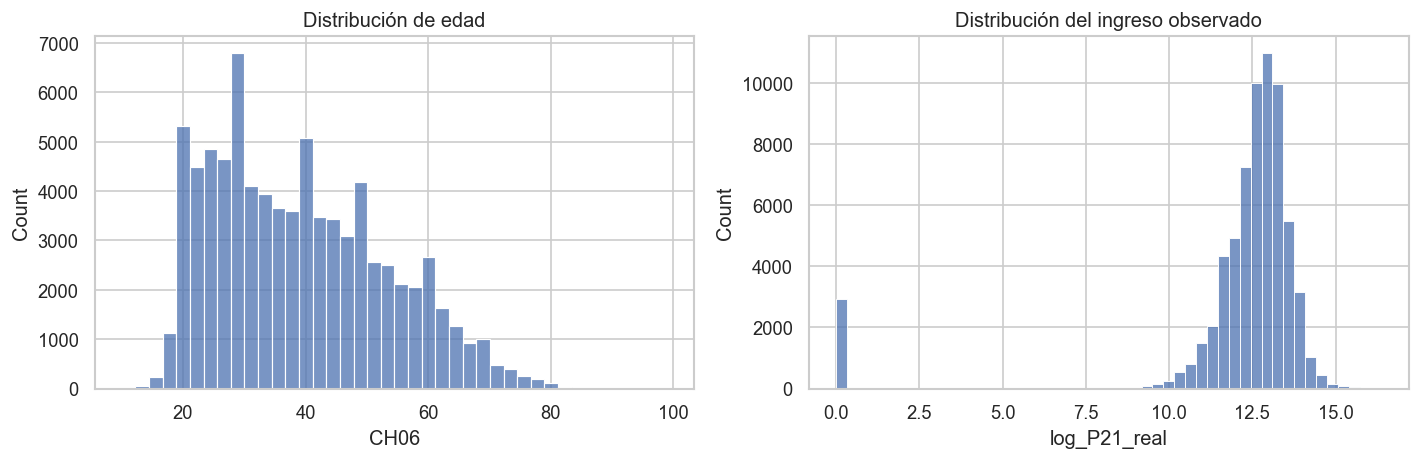

In [18]:
METADATOS = ["id_persona", "ANO4", "TRIMESTRE", "PONDERA"]
ANALITICAS = ["CH04", "CH06", "NIVEL_ED", "REGION", "CAT_OCUP", "CAES", "TAM_EST", "INTENSI", "log_P21_real"]
ACTIVAS_FINAL = ["CH04", "CH06", "NIVEL_ED", "CAT_OCUP", "CAES", "TAM_EST", "INTENSI"]
CATEGORICAS_FINAL = ["CH04", "NIVEL_ED", "CAT_OCUP", "CAES", "TAM_EST", "INTENSI"]
EXTERNAS = ["REGION", "log_P21_real"]
ESPERADAS = METADATOS + ANALITICAS

base, fuente_utilizada = cargar_base_clustering(DATA_PATH)

# --- Registrar la fuente en el reporte de entorno ---
versiones_entorno.loc[
    versiones_entorno["componente"] == "fuente de datos utilizada",
    "version",
] = fuente_utilizada

print(f"Fuente de datos utilizada: {fuente_utilizada}")

if (f := [c for c in ESPERADAS if c not in base.columns]):
    raise KeyError(f"Faltan columnas en la base: {f}")

resumen_universo = pd.DataFrame({
    "indicador": [
        "registros",
        "personas identificadas",
        "combinaciones persona-periodo",
        "duplicados persona-periodo",
    ],
    "valor": [
        len(base),
        base["id_persona"].nunique(),
        len(base[["id_persona", "ANO4", "TRIMESTRE"]].drop_duplicates()),
        base.duplicated(["id_persona", "ANO4", "TRIMESTRE"]).sum(),
    ],
})
display(resumen_universo)
assert resumen_universo["valor"].tolist() == [80300, 47970, 80300, 0], (
    "El universo no coincide con el esperado."
)

auditoria = pd.DataFrame({
    "variable": ESPERADAS,
    "dtype": [str(base[c].dtype) for c in ESPERADAS],
    "n": len(base),
    "n_missing": [base[c].isna().sum() for c in ESPERADAS],
    "pct_missing": [100 * base[c].isna().mean() for c in ESPERADAS],
    "cardinalidad": [base[c].nunique(dropna=True) for c in ESPERADAS],
})
display(auditoria)

frecuencias = []
for c in CATEGORICAS_FINAL:
    t = (
        base[c]
        .value_counts(dropna=False)
        .rename_axis("categoria")
        .reset_index(name="n")
    )
    t["variable"] = c
    t["porcentaje"] = 100 * t["n"] / len(base)
    t["categoria_menor_1pct"] = t["porcentaje"] < 1
    frecuencias.append(t)
frecuencias = pd.concat(frecuencias, ignore_index=True)
display(frecuencias.query("categoria_menor_1pct"))

display(
    base[["CH06", "log_P21_real"]]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .T
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(base["CH06"].dropna(), bins=40, ax=ax[0])
ax[0].set_title("Distribución de edad")
sns.histplot(base["log_P21_real"].dropna(), bins=50, ax=ax[1])
ax[1].set_title("Distribución del ingreso observado")
plt.tight_layout()
plt.show()

## 3. Diagnóstico de valores faltantes

`log_P21_real` presenta 13.989 faltantes (17,42 %). No se imputa el ingreso
ni se eliminan observaciones por su ausencia. La variable no participa en el
FAMD ni en K‑means; se utiliza exclusivamente para caracterizar los perfiles.
Se analiza el patrón de missing por cada variable activa y por periodo.

In [4]:
def missing_por(v):
    return base.groupby(v,dropna=False).log_P21_real.agg(n="size",n_ingreso_observado="count",pct_missing=lambda x:100*x.isna().mean()).reset_index().assign(variable=v).rename(columns={v:"categoria"})
missing_ingreso=pd.concat([missing_por(v) for v in CATEGORICAS_FINAL+["REGION"]],ignore_index=True)
missing_periodo=base.groupby(["ANO4","TRIMESTRE"],dropna=False).log_P21_real.agg(n="size",n_ingreso_observado="count",pct_missing=lambda x:100*x.isna().mean()).reset_index()
display(missing_ingreso); display(missing_periodo)
mask_final=base[ACTIVAS_FINAL].notna().all(axis=1)
elegibilidad=pd.DataFrame({"condicion":["elegibles","fuera por NA en CAES"],"n":[mask_final.sum(),(~mask_final).sum()]})
display(elegibilidad)
assert mask_final.sum()==79751 and (~mask_final).sum()==549
assert base.loc[~mask_final,"CAES"].isna().all()

,categoria,n,n_ingreso_observado,pct_missing,variable
0,1,43605,35187,19.305126,CH04
1,2,36695,31124,15.181905,CH04
2,1,3650,3067,15.972603,NIVEL_ED
3,2,12820,10473,18.307332,NIVEL_ED
4,3,19100,16008,16.188482,NIVEL_ED
5,4,26138,21316,18.448236,NIVEL_ED
6,5,11125,9352,15.937079,NIVEL_ED
7,6,7173,5861,18.290813,NIVEL_ED
8,7,294,234,20.408163,NIVEL_ED
9,1,1772,1439,18.792325,CAT_OCUP


,ANO4,TRIMESTRE,n,n_ingreso_observado,pct_missing
0,2023,4,9114,7833,14.055300
1,2024,1,8652,7366,14.863615
2,2024,2,8951,7576,15.361412
3,2024,3,9167,7537,17.781172
4,2024,4,9109,7335,19.475244
5,2025,1,8656,7046,18.599815
6,2025,2,8989,7383,17.866281
7,2025,3,8916,7185,19.414536
8,2025,4,8746,7050,19.391722


,condicion,n
0,elegibles,79751
1,fuera por NA en CAES,549


## 4. Decisiones metodológicas

El modelo principal es FAMD sin `REGION`, con siete variables activas. `REGION` y `log_P21_real` quedan como externas. Se retienen siete dimensiones por parsimonia. Las dimensiones factoriales sirven para calcular el clustering y los clusters se interpretan con las variables originales. No es necesario explicar por separado los siete ejes.

## 5. Preparación del modelo final

Se convierten los tipos: `CH06` a `float64` y las restantes variables activas
a `category`. El ajuste se realiza sobre 79.751 observaciones elegibles.
Las 549 observaciones con `CAES` faltante permanecen en la base final con
`cluster_final = NA`.

In [5]:
X_final=base.loc[mask_final,ACTIVAS_FINAL].copy()
X_final["CH06"] = pd.to_numeric(
    X_final["CH06"],
    errors="raise"
).astype("float64")
for c in CATEGORICAS_FINAL: X_final[c]=X_final[c].astype("category")
assert len(X_final)==79751 and str(X_final.CH06.dtype)=="float64"
display(X_final.dtypes)

CH04        category
CH06         float64
NIVEL_ED    category
CAT_OCUP    category
CAES        category
TAM_EST     category
INTENSI     category
dtype: object

## 6. FAMD

Se estima una única vez un FAMD de 15 componentes sobre siete variables activas. `CH06` es numérica `float64`.

In [6]:
famd=prince.FAMD(n_components=15,n_iter=5,random_state=SEED,engine="sklearn")
famd=famd.fit(X_final)

## 7. Selección de dimensiones

Se mantienen siete dimensiones mediante una decisión parsimoniosa. Se usan para el clustering, no para interpretar individualmente siete ejes.

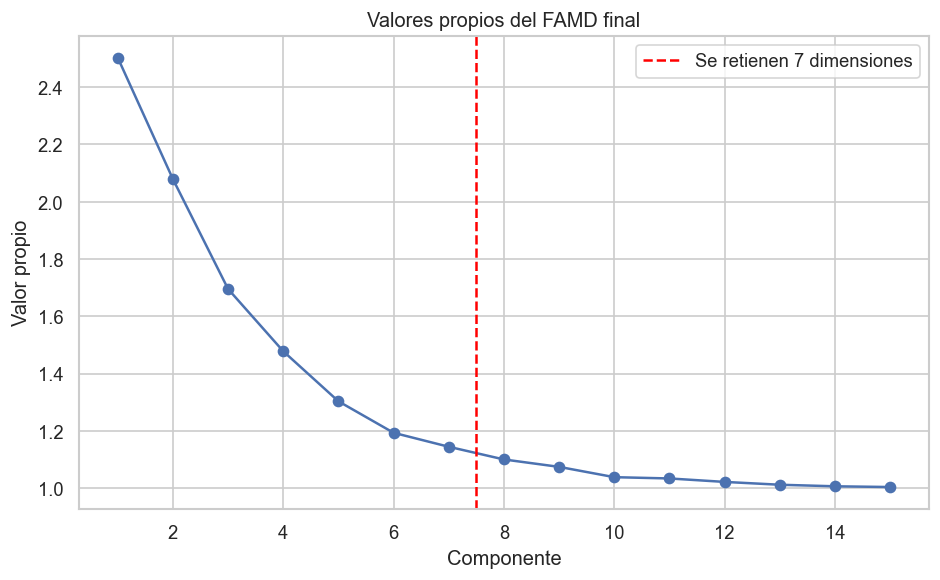

component,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
variable,,,,,,,,,,,,,,,
CH06,0.001933,0.106025,0.000185,0.147008,0.093872,0.029147,0.000036,0.025534,0.001932,0.007929,0.000043,0.000319,0.000622,0.002693,0.000696
CAES,0.325359,0.197512,0.360579,0.343029,0.297904,0.444506,0.570680,0.530986,0.424151,0.532199,0.529834,0.548536,0.587239,0.731791,0.748935
CAT_OCUP,0.165917,0.188535,0.082908,0.045753,0.167757,0.016272,0.020944,0.003303,0.197310,0.004731,0.221325,0.020172,0.049130,0.021853,0.002996
CH04,0.131066,0.030816,0.063904,0.071733,0.030339,0.006775,0.002294,0.018196,0.000753,0.000306,0.000852,0.000966,0.000547,0.000804,0.000334
INTENSI,0.020647,0.040919,0.036985,0.026707,0.071062,0.313098,0.036253,0.033382,0.032333,0.203937,0.020623,0.244554,0.008543,0.008629,0.155636
NIVEL_ED,0.007668,0.047042,0.227043,0.234070,0.197710,0.090882,0.066636,0.139115,0.302063,0.203210,0.221759,0.185328,0.344622,0.217235,0.082753
TAM_EST,0.347422,0.389260,0.229117,0.132830,0.146286,0.100414,0.308916,0.257145,0.042494,0.050454,0.007754,0.000935,0.013287,0.018098,0.009353


component,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
variable,,,,,,,,,,,,,,,
CH06,0.004839,0.220435,0.000313,0.217299,0.122359,0.034788,0.000041,0.028099,0.002076,0.008235,0.000044,0.000326,0.000629,0.002711,0.000699
CAES,0.814371,0.410646,0.611338,0.507046,0.388305,0.530537,0.653291,0.584329,0.455779,0.552762,0.547924,0.560658,0.594416,0.736755,0.752105
CAT_OCUP,0.415288,0.391981,0.140566,0.067630,0.218664,0.019422,0.023976,0.003634,0.212023,0.004914,0.228882,0.020617,0.049731,0.022001,0.003009
CH04,0.328057,0.064069,0.108346,0.106031,0.039545,0.008086,0.002626,0.020024,0.000809,0.000317,0.000881,0.000987,0.000553,0.000809,0.000335
INTENSI,0.051679,0.085075,0.062706,0.039477,0.092626,0.373696,0.041501,0.036735,0.034744,0.211817,0.021327,0.249958,0.008648,0.008687,0.156295
NIVEL_ED,0.019193,0.097805,0.384936,0.345990,0.257706,0.108471,0.076282,0.153090,0.324588,0.211062,0.229331,0.189423,0.348834,0.218709,0.083104
TAM_EST,0.869594,0.809307,0.388452,0.196343,0.190677,0.119849,0.353634,0.282978,0.045663,0.052403,0.008019,0.000956,0.013449,0.018221,0.009393


In [7]:
N_DIMS = 7
coords = famd.row_coordinates(X_final).iloc[:, :N_DIMS]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, 16), famd.eigenvalues_, marker="o")
ax.axvline(
    7.5,
    color="red",
    linestyle="--",
    label="Se retienen 7 dimensiones",
)
ax.set_title("Valores propios del FAMD final")
ax.set_xlabel("Componente")
ax.set_ylabel("Valor propio")
ax.legend()
plt.tight_layout()
plt.savefig(
    OUT_DIR / "famd_scree_plot_final.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

display(famd.column_contributions_)
display(famd.column_coordinates_)

## 8. Evaluación del número de clusters

Se mantiene `k=2` a `k=8`. Gap fue creciente y se usa como criterio complementario, no se afirma que tenga un máximo. `K_FINAL=5` es una decisión explícita, sin ranking automático.

In [8]:
K_VALUES = range(2, 9)
SAMPLE_METRICS = min(5000, len(coords))
rng_metricas = np.random.default_rng(SEED)
sample_idx = rng_metricas.choice(
    len(coords), size=SAMPLE_METRICS, replace=False
)

Z = coords.to_numpy()               # base completa
Z_sample = Z[sample_idx]            # submuestra reproducible


def gap_statistic(Zs, n_clusters, n_refs=10):
    """Gap Statistic sobre una submuestra, sin conservar matrices
    de referencia en memoria.

    Se utiliza un generador local reproducible (rng_gap) de modo que
    la misma secuencia de referencias se emplee para comparar todos
    los valores de k, sin depender del estado global de rng_metricas.

    Parameters
    ----------
    Zs : ndarray de forma (n_sample, n_dims)
    n_clusters : int
    n_refs : int

    Returns
    -------
    gap : float
    error_estandar : float
    """
    rng_gap = np.random.default_rng(SEED)

    observado = KMeans(
        n_clusters=n_clusters, n_init=50, random_state=SEED,
    ).fit(Zs)
    disp_obs = np.log(observado.inertia_)

    mins, maxs = Zs.min(axis=0), Zs.max(axis=0)
    disp_refs = []
    for i in range(n_refs):
        r = rng_gap.uniform(mins, maxs, size=Zs.shape)
        ref_inertia = KMeans(
            n_clusters=n_clusters, n_init=50, random_state=SEED + i + 1,
        ).fit(r).inertia_
        disp_refs.append(np.log(ref_inertia))

    disp_refs = np.array(disp_refs)
    gap = disp_refs.mean() - disp_obs
    se = disp_refs.std(ddof=1) * np.sqrt(1 + 1 / n_refs)
    return gap, se


filas = []
for k in K_VALUES:
    # Inercia, CH, DB y tamaño mínimo sobre la base completa
    m = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(Z)
    lab_full = m.labels_

    # Silhouette sobre la submuestra
    sil = silhouette_score(Z_sample, lab_full[sample_idx])

    # Gap sobre la submuestra
    gap, gap_se = gap_statistic(Z_sample, k)

    filas.append({
        "k": k,
        "inercia": m.inertia_,
        "silhouette": sil,
        "calinski_harabasz": calinski_harabasz_score(Z, lab_full),
        "davies_bouldin": davies_bouldin_score(Z, lab_full),
        "gap_statistic": gap,
        "error_estandar_gap": gap_se,
        "porcentaje_cluster_minimo": (
            100
            * pd.Series(lab_full).value_counts(normalize=True).min()
        ),
    })

metricas_k = pd.DataFrame(filas)
K_FINAL = 5
display(metricas_k)

,k,inercia,silhouette,calinski_harabasz,davies_bouldin,gap_statistic,error_estandar_gap,porcentaje_cluster_minimo
0,2,732688.948264,0.302980,19269.506734,0.948162,1.241725,0.003889,12.393575
1,3,589862.856429,0.269411,21622.379654,1.474671,1.367790,0.003542,12.371005
2,4,505965.659037,0.284949,21212.729963,1.491642,1.441386,0.004737,12.368497
3,5,449182.275297,0.273525,20440.806454,1.469850,1.497274,0.004027,7.251320
4,6,400834.000879,0.282109,20248.598999,1.355243,1.560678,0.004360,5.218743
5,7,363805.737837,0.280158,19943.808600,1.232134,1.613508,0.004840,4.837557
6,8,332264.422353,0.277755,19798.610054,1.303815,1.660981,0.004269,4.797432


### Justificación de la solución con cinco clusters

La solución de cinco clusters se seleccionó como compromiso entre calidad
interna, tamaño de los grupos e interpretabilidad para el ABM. Aunque k=2
presentó mayor separación geométrica y k=3 maximizó Calinski‑Harabasz,
ambas soluciones resultaron demasiado agregadas para representar la
heterogeneidad laboral analizada. Con k=5, el grupo muestral más pequeño
representó aproximadamente el 7,25 % de las observaciones. Gap Statistic
mostró una tendencia creciente y se consideró un criterio complementario,
no decisivo.

## 9. Estimación final con k=5

Única estimación final: `k=5`, `n_init=50`, `random_state=42`.

In [9]:
km_final = KMeans(n_clusters=K_FINAL, n_init=50, random_state=42)
labels_final = km_final.fit_predict(coords) + 1

base_final = base[METADATOS + ANALITICAS].copy()
base_final["cluster_final"] = pd.Series(
    pd.NA, index=base_final.index, dtype="Int64"
)
base_final.loc[X_final.index, "cluster_final"] = labels_final

assert len(base_final) == 80300
assert base_final["cluster_final"].notna().sum() == 79751
assert base_final["cluster_final"].isna().sum() == 549
assert set(
    base_final["cluster_final"].dropna().astype(int).unique()
) == {1, 2, 3, 4, 5}

display(base_final["cluster_final"].value_counts(dropna=False).sort_index())

cluster_final
1       24571
2       19286
3        5783
4        9867
5       20244
<NA>      549
Name: count, dtype: Int64

## 10. Validación

Se evalúa la estabilidad de la partición mediante ARI con cinco semillas
distintas. Un ARI superior a 0,999 demuestra estabilidad frente a
inicializaciones, pero no implica separación perfecta ni existencia de
grupos naturales. Se reporta además la Silhouette media por cluster sobre
la submuestra fija de 5.000 observaciones, los tamaños absolutos y los
porcentajes ponderados y no ponderados.

In [10]:
estabilidad_semillas = []
for s in [7, 21, 42, 84, 123]:
    l = KMeans(n_clusters=5, n_init=30, random_state=s).fit_predict(coords)
    estabilidad_semillas.append({
        "semilla": s,
        "ARI": adjusted_rand_score(labels_final - 1, l),
    })
estabilidad_semillas = pd.DataFrame(estabilidad_semillas)

sil = silhouette_samples(
    Z_sample,
    (labels_final - 1)[sample_idx]
)

silhouette_por_cluster = (
    pd.DataFrame({
        "cluster_final": labels_final[sample_idx],
        "silhouette": sil,
    })
    .groupby("cluster_final", as_index=False)
    .agg(
        silhouette_medio=("silhouette", "mean"),
        silhouette_mediana=("silhouette", "median"),
        n_muestra=("silhouette", "size"),
    )
)

asignados = base_final.dropna(subset=["cluster_final"]).copy()
asignados["cluster_final"] = asignados["cluster_final"].astype(int)

tamanios = (
    asignados
    .groupby("cluster_final")
    .agg(
        n=("cluster_final", "size"),
        ponderacion=("PONDERA", "sum"),
    )
    .reset_index()
)
tamanios["porcentaje_no_ponderado"] = (
    100 * tamanios["n"] / tamanios["n"].sum()
)
tamanios["porcentaje_ponderado"] = (
    100 * tamanios["ponderacion"] / tamanios["ponderacion"].sum()
)

# --- Verificación de cierre al 100 % ---
assert abs(tamanios["porcentaje_no_ponderado"].sum() - 100) < 0.01, (
    "Los porcentajes no ponderados no suman 100."
)
assert abs(tamanios["porcentaje_ponderado"].sum() - 100) < 0.01, (
    "Los porcentajes ponderados no suman 100."
)

display(estabilidad_semillas)
display(silhouette_por_cluster)
display(tamanios)

# --- Advertencias por clusters muy pequeños ---
UMBRAL = 5.0
for _, row in tamanios.iterrows():
    if row["porcentaje_no_ponderado"] < UMBRAL:
        print(
            f"Advertencia: el cluster {row['cluster_final']} representa "
            f"{row['porcentaje_no_ponderado']:.2f} % de las observaciones "
            f"(< {UMBRAL} %)."
        )
    if row["porcentaje_ponderado"] < UMBRAL:
        print(
            f"Advertencia: el cluster {row['cluster_final']} representa "
            f"{row['porcentaje_ponderado']:.2f} % de la población ponderada "
            f"(< {UMBRAL} %)."
        )

,semilla,ARI
0,7,0.999795
1,21,0.999854
2,42,1.000000
3,84,0.999854
4,123,0.999670


,cluster_final,silhouette_medio,silhouette_mediana,n_muestra
0,1,0.273731,0.278075,1549
1,2,0.138944,0.145291,1201
2,3,0.216843,0.207233,347
3,4,0.673561,0.692497,646
4,5,0.211916,0.231622,1257


,cluster_final,n,ponderacion,porcentaje_no_ponderado,porcentaje_ponderado
0,1,24571,15239135,30.809645,30.209564
1,2,19286,13676028,24.182769,27.110912
2,3,5783,3448486,7.251320,6.836166
3,4,9867,5837347,12.372259,11.571766
4,5,20244,12243740,25.384008,24.271591


## 11. Perfilamiento

Tabla única de perfiles. Los nombres son descriptivos provisionales.

In [ ]:
nombres_clusters = {
    1: (
        "Cuentapropismo predominantemente unipersonal "
        "y sectorialmente diverso"
    ),
    2: (
        "Asalariados informales jóvenes vinculados "
        "al comercio"
    ),
    3: (
        "Asalariados informales en establecimientos "
        "grandes"
    ),
    4: (
        "Asalariados informales en hogares particulares"
    ),
    5: (
        "Inserciones informales mixtas en pequeños "
        "establecimientos"
    ),
}


def modo(x):
    y = x.dropna()
    return y.mode().iloc[0] if len(y) else pd.NA


def pct_modo(x):
    y = x.dropna()
    return 100 * (y == y.mode().iloc[0]).mean() if len(y) else np.nan


perfil = (
    asignados
    .groupby("cluster_final")
    .agg(
        n=("cluster_final", "size"),
        suma_pondera=("PONDERA", "sum"),
        mediana_edad=("CH06", "median"),
        ric_edad=("CH06", lambda x: x.quantile(0.75) - x.quantile(0.25)),
        mediana_log_P21_real=("log_P21_real", "median"),
        ric_log_P21_real=(
            "log_P21_real",
            lambda x: x.quantile(0.75) - x.quantile(0.25),
        ),
        n_ingresos_observados=("log_P21_real", "count"),
        porcentaje_faltante_ingreso=(
            "log_P21_real",
            lambda x: 100 * x.isna().mean(),
        ),
    )
)

perfil["nombre_descriptivo"] = perfil.index.map(nombres_clusters)
perfil["porcentaje_no_ponderado"] = 100 * perfil["n"] / perfil["n"].sum()
perfil["porcentaje_ponderado"] = (
    100 * perfil["suma_pondera"] / perfil["suma_pondera"].sum()
)

for v in CATEGORICAS_FINAL:
    perfil[f"moda_{v}"] = (
        asignados.groupby("cluster_final")[v].apply(modo)
    )
    perfil[f"porcentaje_modal_{v}"] = (
        asignados.groupby("cluster_final")[v].apply(pct_modo)
    )


def dist_ponderada(v, prefijo):
    t = (
        pd.crosstab(
            asignados["cluster_final"],
            asignados[v],
            values=asignados["PONDERA"],
            aggfunc="sum",
            normalize="index",
        )
        * 100
    )
    t.columns = [f"{prefijo}_{c}" for c in t.columns]
    return t


perfil = (
    perfil
    .join(dist_ponderada("CAT_OCUP", "pct_CAT_OCUP"))
    .join(dist_ponderada("REGION", "pct_REGION"))
)
perfil = perfil.reset_index()
display(perfil)

# --- Distribuciones detalladas ---
distribuciones = []
for v in CATEGORICAS_FINAL + ["REGION"]:
    t = (
        asignados
        .groupby(["cluster_final", v], dropna=False)
        .agg(
            n=("cluster_final", "size"),
            ponderacion=("PONDERA", "sum"),
        )
        .reset_index()
        .rename(columns={v: "categoria"})
    )
    t["porcentaje_no_ponderado"] = (
        100 * t["n"] / t.groupby("cluster_final")["n"].transform("sum")
    )
    t["porcentaje_ponderado"] = (
        100
        * t["ponderacion"]
        / t.groupby("cluster_final")["ponderacion"].transform("sum")
    )
    t["variable"] = v
    distribuciones.append(t)
distribuciones_categoricas = pd.concat(distribuciones, ignore_index=True)

# --- Cuentapropismo (CAT_OCUP == 2) ---
# Se compara en formato numérico para ser robusto tanto si la variable
# se lee con codificación numérica (CSV) como categórica (parquet).
es_cuentapropista = (
    pd.to_numeric(asignados["CAT_OCUP"], errors="coerce") == 2
)
cp = asignados.loc[es_cuentapropista]

perfil_cuentapropismo = (
    cp.groupby("cluster_final")
    .agg(
        n=("cluster_final", "size"),
        ponderacion=("PONDERA", "sum"),
    )
    .reset_index()
)
perfil_cuentapropismo["porcentaje_no_ponderado"] = (
    100
    * perfil_cuentapropismo["n"]
    / perfil_cuentapropismo["n"].sum()
)
perfil_cuentapropismo["porcentaje_ponderado"] = (
    100
    * perfil_cuentapropismo["ponderacion"]
    / perfil_cuentapropismo["ponderacion"].sum()
)
display(perfil_cuentapropismo)

# --- Observaciones sin cluster ---
sin_cluster = base_final["cluster_final"].isna()
casos_sin_cluster = pd.DataFrame({
    "concepto": [
        "observaciones sin cluster",
        "suma PONDERA sin cluster",
        "porcentaje ponderado sobre universo original",
    ],
    "valor": [
        int(sin_cluster.sum()),
        base_final.loc[sin_cluster, "PONDERA"].sum(),
        100
        * base_final.loc[sin_cluster, "PONDERA"].sum()
        / base_final["PONDERA"].sum(),
    ],
})
display(casos_sin_cluster)

,cluster_final,n,suma_pondera,mediana_edad,ric_edad,mediana_log_P21_real,ric_log_P21_real,n_ingresos_observados,porcentaje_faltante_ingreso,nombre_descriptivo,...,pct_CAT_OCUP_1,pct_CAT_OCUP_2,pct_CAT_OCUP_3,pct_CAT_OCUP_4,pct_REGION_1,pct_REGION_40,pct_REGION_41,pct_REGION_42,pct_REGION_43,pct_REGION_44
0,1,24571,15239135,43.0,23.0,12.634731,1.279738,19542,20.467217,Cuentapropismo predominantemente unipersonal y...,...,0.000000,97.572520,2.427480,0.000000,51.280981,12.158873,6.137921,7.124368,20.666094,2.631764
1,2,19286,13676028,32.0,18.0,12.922412,1.040033,15487,19.698227,Asalariados informales jóvenes vinculados al c...,...,0.042995,1.327513,98.629492,0.000000,55.812565,9.886920,4.725670,6.908409,21.020489,1.645946
2,3,5783,3448486,34.0,18.0,12.922412,1.012243,5221,9.718139,Asalariados informales en establecimientos gra...,...,0.008149,0.119560,99.867913,0.004379,51.571965,10.865029,4.647431,10.033824,20.296791,2.584960
3,4,9867,5837347,43.0,20.0,12.191552,0.989008,8685,11.979325,Asalariados informales en hogares particulares,...,0.000000,0.000000,100.000000,0.000000,50.496107,11.603508,5.919727,7.734747,21.581002,2.664909
4,5,20244,12243740,33.0,20.0,12.829142,0.985065,16995,16.049200,Inserciones informales mixtas en pequeños esta...,...,7.502961,19.826907,69.311681,3.358451,48.279578,14.107258,5.254996,8.152346,21.807577,2.398246


,cluster_final,n,ponderacion,porcentaje_no_ponderado,porcentaje_ponderado
0,1,24152,14869208,86.048169,85.052261
1,2,245,181551,0.872880,1.038477
2,3,12,4123,0.042753,0.023584
3,5,3659,2427555,13.036198,13.885679


,concepto,valor
0,observaciones sin cluster,549.000000
1,suma PONDERA sin cluster,458115.000000
2,porcentaje ponderado sobre universo original,0.899979


### Cuentapropismo

La distribución del cuentapropismo (CAT_OCUP = 2) entre los clusters se calcula
directamente desde la corrida final. La mayor parte se concentra en el cluster 1,
con una fracción secundaria en el cluster 5. El cluster 1 es homogéneo en posición
ocupacional y escala unipersonal, pero heterogéneo en rama, educación e intensidad
laboral. Esta evidencia no permite caracterizar al cluster 1 mediante un único
perfil de actividad ni de calificación.

## 12. Sensibilidad de REGION

No se reestima ningún modelo. `REGION` se excluyó por parsimonia y alineación con el objetivo del ABM, sin afirmar que carezca completamente de información.

In [12]:
metricas_sensibilidad_region=pd.DataFrame({"metrica":["Silhouette","Calinski-Harabasz","Davies-Bouldin","ARI entre particiones"],"con_REGION":[0.263886,16864.836482,1.442254,np.nan],"sin_REGION":[0.273525,20440.806454,1.469850,np.nan],"valor_comparacion":[np.nan,np.nan,np.nan,0.628452]})
display(metricas_sensibilidad_region)

,metrica,con_REGION,sin_REGION,valor_comparacion
0,Silhouette,0.263886,0.273525,NaN
1,Calinski-Harabasz,16864.836482,20440.806454,NaN
2,Davies-Bouldin,1.442254,1.469850,NaN
3,ARI entre particiones,NaN,NaN,0.628452


## 13. Limitaciones

- Tipos analíticos, no grupos naturales.
- Separación desigual.
- Ingreso externo al clustering y missing no homogéneo.
- Unidad persona-trimestre y repetición de personas entre periodos.
- 549 observaciones sin cluster.
- Concentración del cuentapropismo.
- Ausencia de medición directa de vulnerabilidad.
- Necesidad de combinar perfiles y transiciones en la fase del ABM.

## 14. Conclusión metodológica y exportación

La solución de cinco clusters constituye una tipología empírica estable
y útil para calibrar el modelo basado en agentes. La evidencia no
permite afirmar la existencia de cinco grupos naturales completamente
separados, ni ordenar directamente los perfiles por vulnerabilidad.
La estabilidad ante inicializaciones (ARI > 0,999) respalda la
reproducibilidad de la partición, pero no debe interpretarse como
prueba de separación perfecta.

A continuación se exportan todos los productos del análisis.

In [13]:
# --- Descripción resumida de clusters ---
descripcion_final_clusters = perfil[
    [
        "cluster_final",
        "nombre_descriptivo",
        "n",
        "porcentaje_no_ponderado",
        "porcentaje_ponderado",
    ]
].copy()

# --- Conclusiones (texto plano) ---
conclusiones = (
    "Modelo final: FAMD sin REGION y K-means con k=5. "
    "Siete variables activas y siete dimensiones. "
    "Ajuste sobre 79.751 observaciones; "
    "549 permanecen con cluster_final = NA. "
    "Los nombres son descriptivos provisionales. "
    "ARI > 0,999 indica estabilidad ante inicializaciones, "
    "no separación perfecta. "
    "Los clusters son tipos analíticos y deben combinarse "
    "con transiciones en el ABM.\n"
)

# --- Exportaciones (index=False) ---

# Parquet: exportación directa con PyArrow
import pyarrow as pa
import pyarrow.parquet as pq

tabla_salida = pa.Table.from_pandas(
    base_final,
    preserve_index=False,
)
pq.write_table(
    tabla_salida,
    OUT_DIR / "base_final_clusters_sin_region.parquet",
)

# Verificación de la exportación Parquet
tabla_verificacion = pq.read_table(
    OUT_DIR / "base_final_clusters_sin_region.parquet",
)
assert tabla_verificacion.num_rows == 80300
assert tabla_verificacion.num_columns == len(base_final.columns)

# CSV
base_final.to_csv(
    OUT_DIR / "base_final_clusters_sin_region.csv", index=False
)
perfil.to_csv(
    OUT_DIR / "tabla_final_perfiles_clustering.csv", index=False
)
descripcion_final_clusters.to_csv(
    OUT_DIR / "descripcion_final_clusters.csv", index=False
)
metricas_k.to_csv(
    OUT_DIR / "metricas_seleccion_k.csv", index=False
)
metricas_sensibilidad_region.to_csv(
    OUT_DIR / "metricas_sensibilidad_region.csv", index=False
)
estabilidad_semillas.to_csv(
    OUT_DIR / "estabilidad_semillas.csv", index=False
)
silhouette_por_cluster.to_csv(
    OUT_DIR / "silhouette_por_cluster.csv", index=False
)
distribuciones_categoricas.to_csv(
    OUT_DIR / "distribuciones_categoricas_clusters.csv", index=False
)
perfil_cuentapropismo.to_csv(
    OUT_DIR / "perfil_cuentapropismo.csv", index=False
)
casos_sin_cluster.to_csv(
    OUT_DIR / "casos_sin_cluster.csv", index=False
)
versiones_entorno.to_csv(
    OUT_DIR / "versiones_entorno_clustering.csv", index=False
)
with open(
    OUT_DIR / "conclusiones_clustering.txt", "w", encoding="utf-8"
) as f:
    f.write(conclusiones)

# --- Verificación ---
archivos = [
    "base_final_clusters_sin_region.parquet",
    "base_final_clusters_sin_region.csv",
    "tabla_final_perfiles_clustering.csv",
    "descripcion_final_clusters.csv",
    "metricas_seleccion_k.csv",
    "metricas_sensibilidad_region.csv",
    "estabilidad_semillas.csv",
    "silhouette_por_cluster.csv",
    "distribuciones_categoricas_clusters.csv",
    "perfil_cuentapropismo.csv",
    "casos_sin_cluster.csv",
    "versiones_entorno_clustering.csv",
    "conclusiones_clustering.txt",
    "famd_scree_plot_final.png",
]
faltan = [a for a in archivos if not (OUT_DIR / a).exists()]
if faltan:
    print(f"Aviso: los siguientes archivos no se generaron: {faltan}")
else:
    print(f"Exportación completada en {OUT_DIR}")

Exportación completada en C:\Users\tomas\OneDrive\Master Granada\TFM\Salidas\07_clustering
